<a href="https://colab.research.google.com/github/Mahadeva77/DAV-Lab---4IK25CS097/blob/main/4ik25cs097_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6,
                    1, 2, 3, 4, 5, 6],

    "Result": [
        "Fail", "Fail", "Fail", "Fail", "Pass", "Pass",
        "Fail", "Fail", "Fail", "Pass", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

In [ ]:
print("STUDENT DATASET")
print(df)

STUDENT DATASET
    Study_Hours Result
0             1   Fail
1             2   Fail
2             3   Fail
3             4   Fail
4             5   Pass
5             6   Pass
6             1   Fail
7             2   Fail
8             3   Fail
9             4   Pass
10            5   Pass
11            6   Pass


In [ ]:
X = df[["Study_Hours"]]
y = df["Result"]

# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [ ]:
print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

# Step 5: Create Logistic Regression Model
model = LogisticRegression()

# Step 6: Train the Model
model.fit(X_train, y_train)

print("\nModel Trained Successfully!")


Training Records: 9
Testing Records: 3

Model Trained Successfully!


In [ ]:
print("\nLEARNED MODEL PARAMETERS")
print("Intercept:", model.intercept_[0])
print("Coefficient:", model.coef_[0][0])


LEARNED MODEL PARAMETERS
Intercept: -4.67287814115274
Coefficient: 1.3248119801450653


In [ ]:
y_pred = model.predict(X_test)

print("\nACTUAL RESULTS:")
print(y_test.values)

print("\nPREDICTED RESULTS:")
print(y_pred)

# Step 9: Prediction Probabilities
y_prob = model.predict_proba(X_test)

print("\nPREDICTED PROBABILITIES:")
print(y_prob)


ACTUAL RESULTS:
['Pass' 'Fail' 'Fail']

PREDICTED RESULTS:
['Pass' 'Fail' 'Pass']

PREDICTED PROBABILITIES:
[[0.03640399 0.96359601]
 [0.6678423  0.3321577 ]
 [0.34833413 0.65166587]]


In [ ]:
comparison = pd.DataFrame({
    "Study_Hours": X_test["Study_Hours"].values,
    "Actual_Result": y_test.values,
    "Predicted_Result": y_pred
})

print("\nACTUAL VS PREDICTED RESULTS")
print(comparison)


ACTUAL VS PREDICTED RESULTS
   Study_Hours Actual_Result Predicted_Result
0            6          Pass             Pass
1            3          Fail             Fail
2            4          Fail             Pass


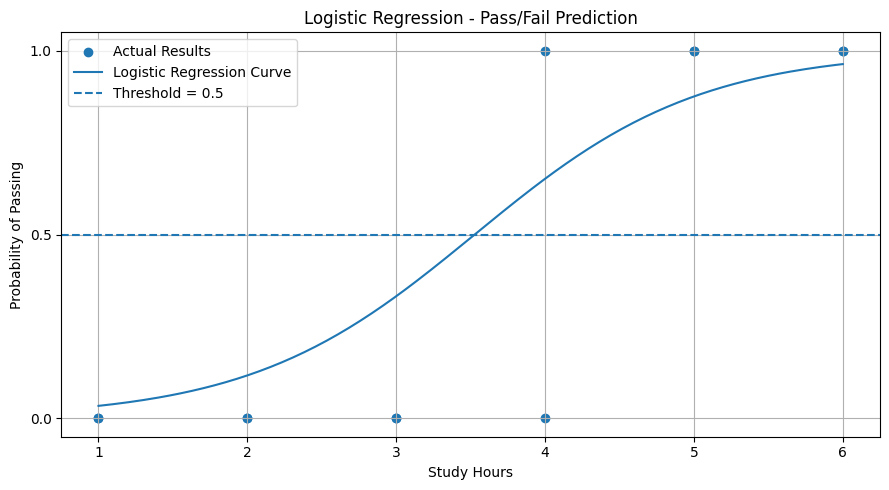

In [ ]:
study_hours = pd.DataFrame({
    "Study_Hours": np.linspace(
        df["Study_Hours"].min(),
        df["Study_Hours"].max(),
        200
    )
})

pass_index = list(model.classes_).index("Pass")

probabilities = model.predict_proba(
    study_hours
)[:, pass_index]

plt.figure(figsize=(9, 5))

plt.scatter(
    df["Study_Hours"],
    df["Result"].map({"Fail": 0, "Pass": 1}),
    label="Actual Results"
)

plt.plot(
    study_hours["Study_Hours"],
    probabilities,
    label="Logistic Regression Curve"
)

plt.axhline(
    y=0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression - Pass/Fail Prediction")
plt.yticks([0, 0.5, 1])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL EVALUATION METRICS")
print("Accuracy:", accuracy * 100, "%")


MODEL EVALUATION METRICS
Accuracy: 66.66666666666666 %



CONFUSION MATRIX
[[1 1]
 [0 1]]


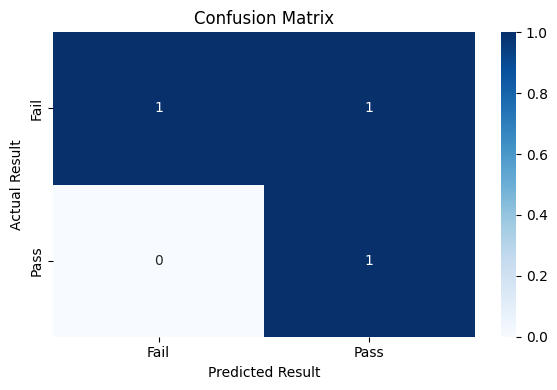

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

print("\nCONFUSION MATRIX")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import precision_score

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

print("\nPrecision:", precision)


Precision: 0.5


In [ ]:
recall = recall_score(
    y_test, y_pred,
    pos_label="Pass",
    zero_division=0
)

print("Recall:", recall)

Recall: 1.0


In [ ]:
f1 = f1_score(
    y_test, y_pred,
    pos_label="Pass",
    zero_division=0
)

print("F1-Score:", f1)

F1-Score: 0.6666666666666666


In [ ]:
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    labels=["Fail", "Pass"],
    zero_division=0
))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fail       1.00      0.50      0.67         2
        Pass       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3



In [ ]:
new_student = pd.DataFrame({
    "Study_Hours": [5]
})

prediction = model.predict(new_student)
probability = model.predict_proba(new_student)

print("\nNEW STUDENT DETAILS")
print(new_student)

print("Probability of Fail:", probability[0][0])
print("Probability of Pass:", probability[0][1])

print("\nPREDICTED STUDENT RESULT:", prediction[0])


NEW STUDENT DETAILS
   Study_Hours
0            5
Probability of Fail: 0.12442455650005035
Probability of Pass: 0.8755754434999496

PREDICTED STUDENT RESULT: Pass
